# Arsenal 2–0 Everton — match report

Premier League 2026/27, 24 October 2026. Each chart from the working notebook (`Arsenal_v_Everton.ipynb`) is rewritten here as a reusable `draw_...(ax, team)` function, and the last cell puts them all on one page and saves it as `match_report.png`.

Needs `arsenal_everton.csv` in the same folder (it's in this repo, or regenerate it by running the first section of `Arsenal_v_Everton.ipynb`).

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from mplsoccer import Pitch

HOME, AWAY = "Arsenal", "Everton"
COLOURS = {"Arsenal": "red", "Everton": "blue"}
CMAPS = {"Arsenal": "Reds", "Everton": "Blues"}

## Load the events and build the extra columns

Distance to goal (in metres), progressive passes, set pieces, the guessed receiver of each pass, and the xT added by every completed pass.

In [2]:
events = pd.read_csv("arsenal_everton.csv")

# distance to goal, in metres
events["dist_start"] = np.sqrt(((100 - events["x"]) * 1.05)**2 + ((50 - events["y"]) * 0.68)**2)
events["dist_end"] = np.sqrt(((100 - events["end_x"]) * 1.05)**2 + ((50 - events["end_y"]) * 0.68)**2)
events["is_progressive"] = events["dist_end"] <= 0.75 * events["dist_start"]

# set pieces, as a COLUMN so filtered tables keep it
events["set_piece"] = events["qualifiers"].str.contains("CornerTaken|ThrowIn", na=False)

# guessed receiver: the next event's player and team
events["next_player"] = events["player"].shift(-1)
events["next_team"] = events["team"].shift(-1)

# completed passes for both teams, with xT added
passes_ok = events[(events["type"] == "Pass") & (events["outcome_type"] == "Successful")].copy()

xt_grid = pd.read_csv(
    "https://raw.githubusercontent.com/mckayjohns/youtube-videos/main/data/xT_Grid.csv",
    header=None,
).values

passes_ok["start_col"] = np.clip((passes_ok["x"] / 100 * 12).astype(int), 0, 11)
passes_ok["start_row"] = np.clip((passes_ok["y"] / 100 * 8).astype(int), 0, 7)
passes_ok["end_col"] = np.clip((passes_ok["end_x"] / 100 * 12).astype(int), 0, 11)
passes_ok["end_row"] = np.clip((passes_ok["end_y"] / 100 * 8).astype(int), 0, 7)
passes_ok["xt"] = np.clip(
    xt_grid[passes_ok["end_row"], passes_ok["end_col"]]
    - xt_grid[passes_ok["start_row"], passes_ok["start_col"]],
    0, None,
)


def completed_passes(team):
    return passes_ok[passes_ok["team"] == team]

Quick check — `[events, Arsenal completed passes, Everton completed passes, Arsenal xT, Everton xT]`:

In [3]:
[
    len(events),
    len(completed_passes("Arsenal")),
    len(completed_passes("Everton")),
    round(completed_passes("Arsenal")["xt"].sum(), 2),
    round(completed_passes("Everton")["xt"].sum(), 2),
]

[1502, 481, 331, np.float64(2.36), np.float64(0.91)]

## Pass end zones

In [4]:

def draw_pass_end_zones(ax, team):
    passes = completed_passes(team)                                    # 1. this team's completed passes (use the helper)

    pitch = Pitch(pitch_type="opta", line_zorder=2)    # 2. pitch into the box we were given
    pitch.draw(ax=ax)

    stats = pitch.bin_statistic(passes["end_x"], passes["end_y"],        # 3. count where the passes ended
                                statistic="count", bins=(6, 5), normalize=True)
    pitch.heatmap(stats, ax=ax, cmap=CMAPS[team], edgecolors="white")
    pitch.label_heatmap(stats, ax=ax, str_format="{:.0%}",
                        ha="center", va="center", fontsize=8)

    ax.set_title(f"{team}: pass end zones")            # 4. title

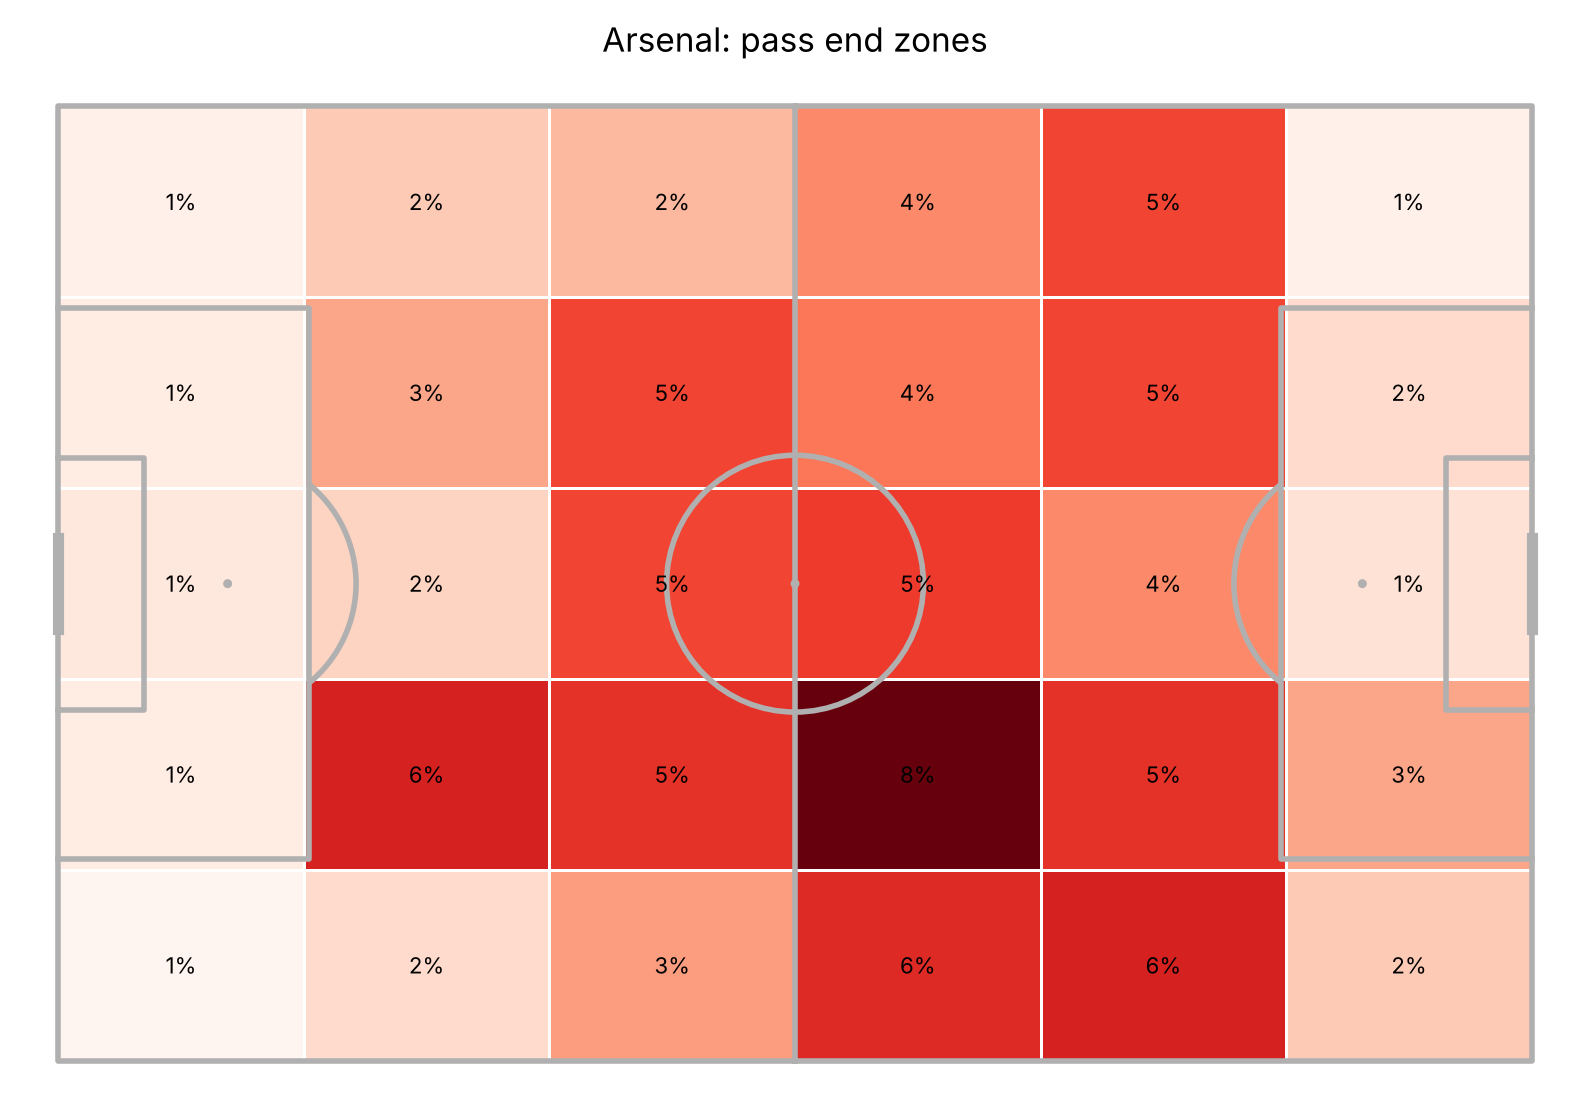

In [5]:
fig, ax = plt.subplots(figsize=(10, 7))
draw_pass_end_zones(ax, "Arsenal")
plt.show()

## Progressive passes

In [6]:
def draw_progressive(ax, team):
    passes = completed_passes(team)
    prog = passes[(passes["is_progressive"]) & (~passes["set_piece"])]       # progressive, and NOT a set piece

    pitch = Pitch(pitch_type="opta", line_zorder=2)
    pitch.draw(ax=ax)

    pitch.arrows(prog["x"], prog["y"], prog["end_x"], prog["end_y"],
                 ax=ax, width=1.5, headwidth=5, color=COLOURS[team])

    ax.set_title(f"{team}: {len(prog)} progressive passes")

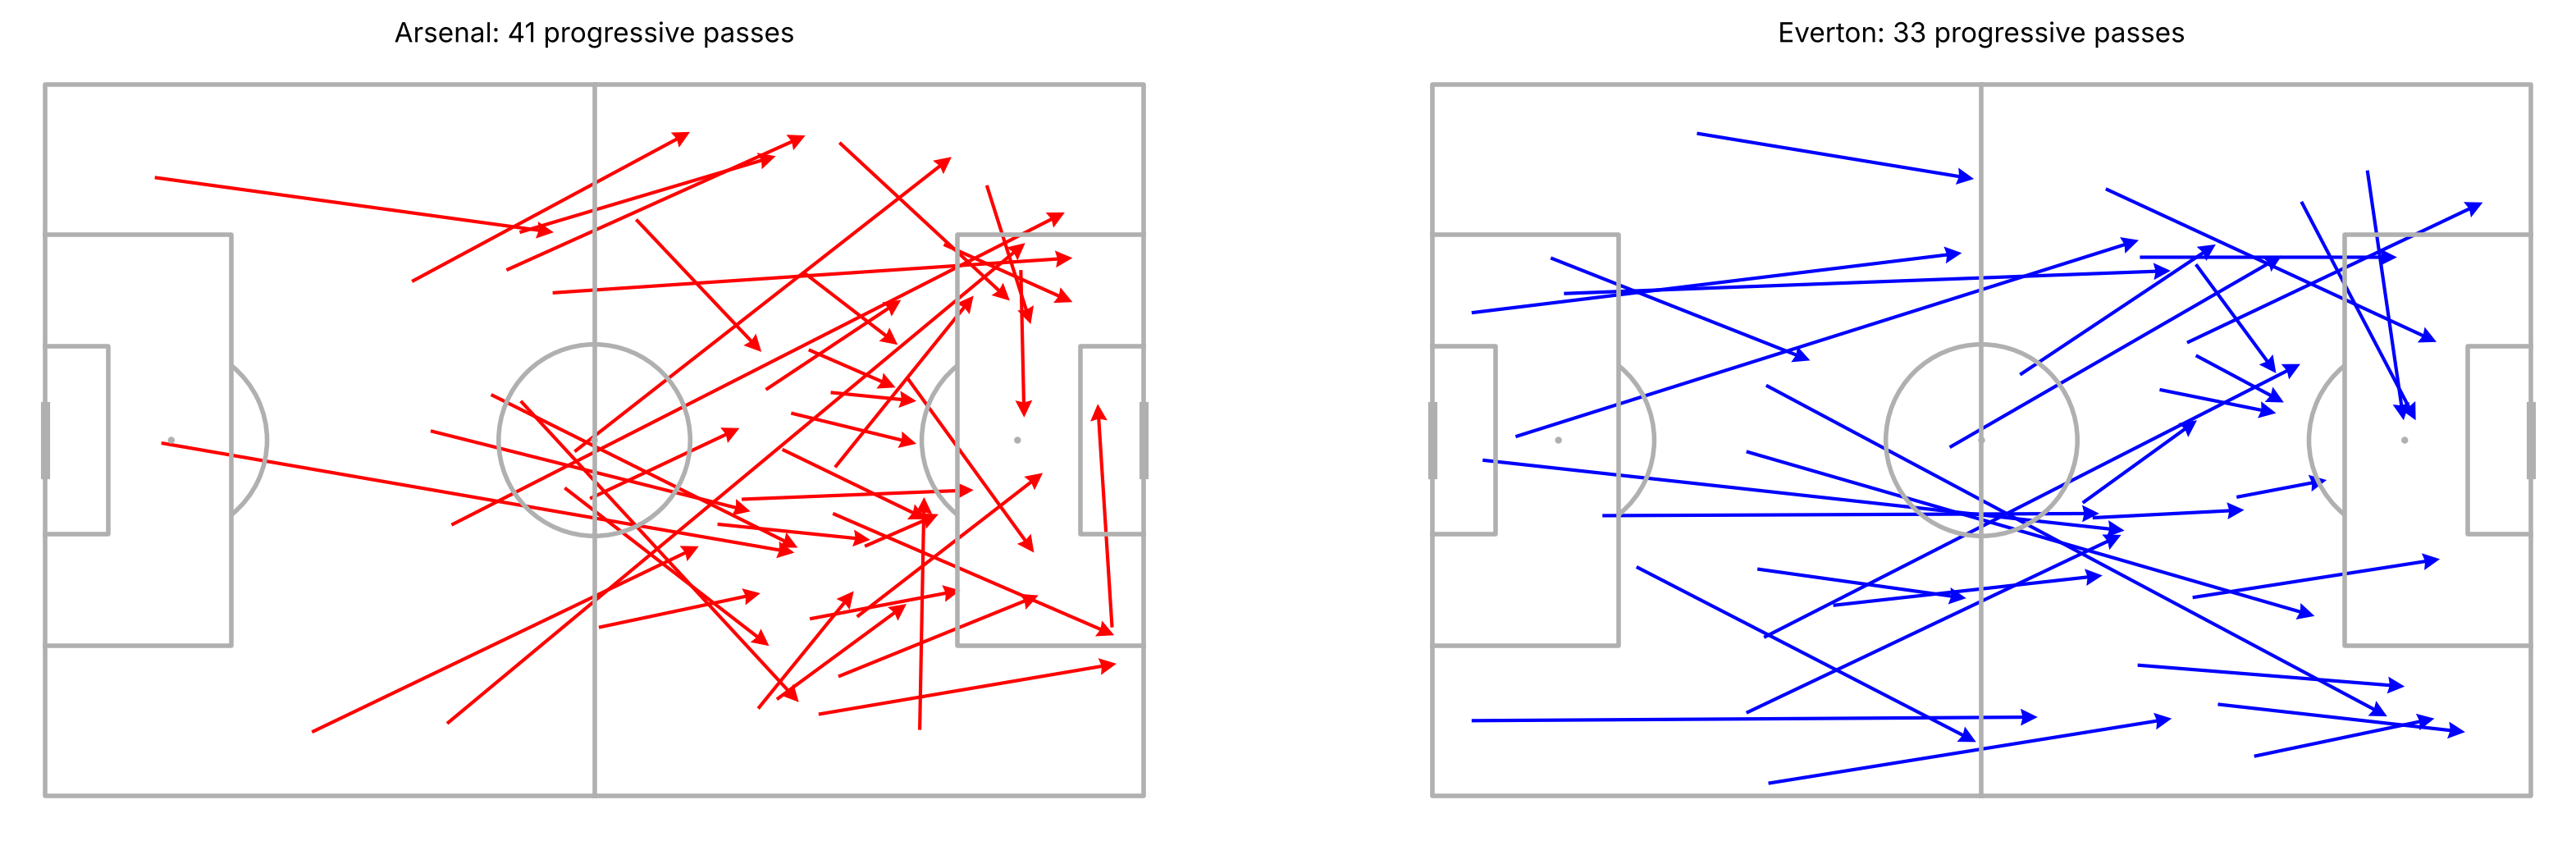

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(20, 7))
draw_progressive(axes[0], "Arsenal")
draw_progressive(axes[1], "Everton")
plt.show()

## Shot map (both teams)

In [8]:
def draw_shot_map_both(ax):
    pitch = Pitch(pitch_type="opta", line_zorder=2)
    pitch.draw(ax=ax)

    for team, flip in [(HOME, False), (AWAY, True)]:
        shots = events[(events["team"] == team) & (events["is_shot"] == True)].copy()
        if flip:
            shots["x"] = 100 - shots["x"]
            shots["y"] = 100 - shots["y"]
        goals = shots[shots["is_goal"] == True]

        pitch.scatter(shots["x"], shots["y"], ax=ax, s=120, color="none",
                      edgecolors=COLOURS[team], linewidth=2)
        pitch.scatter(goals["x"], goals["y"], ax=ax, s=250, color=COLOURS[team],
                      edgecolors="black",
                      label=f"{team} ({len(shots)} shots, {len(goals)} goals)")

    ax.legend(loc="upper center", fontsize=8)
    ax.set_title("Shot map (filled = goal)")

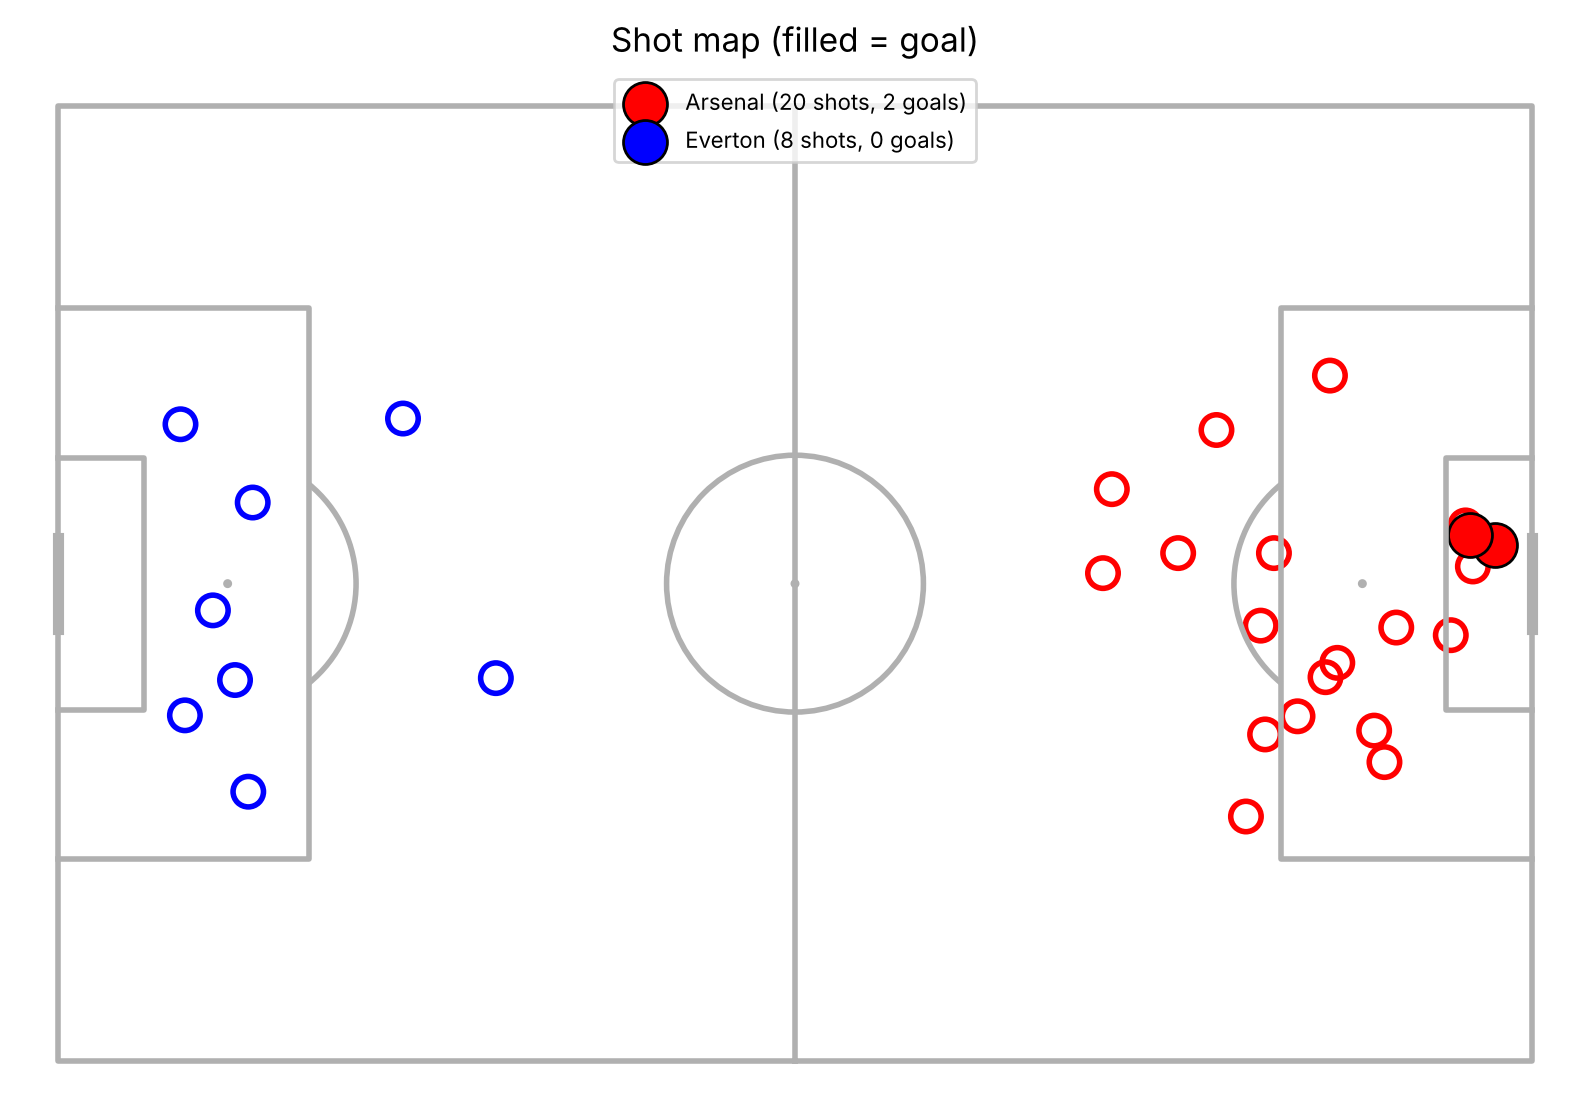

In [9]:
fig, ax = plt.subplots(figsize=(10, 7))
draw_shot_map_both(ax)
plt.show()

## Chance creation

In [10]:
def draw_chance_creation(ax, team):
    kp = events[(events["team"] == team) & (events["type"] == "Pass")
                & (events["qualifiers"].str.contains("KeyPass", na=False))]

    pitch = Pitch(pitch_type="opta", line_zorder=2)
    pitch.draw(ax=ax)

    stats = pitch.bin_statistic(kp["x"], kp["y"], statistic="count", bins=(6, 5))   # where they STARTED
    pitch.heatmap(stats, ax=ax, cmap=CMAPS[team], edgecolors="white")
    pitch.label_heatmap(stats, ax=ax, str_format="{:.0f}", ha="center", va="center", fontsize=8)

    pitch.arrows(kp["x"], kp["y"], kp["end_x"], kp["end_y"],
                 ax=ax, width=2, headwidth=5, color="black", zorder=3)

    ax.set_title(f"{team}: {len(kp)} chances created")

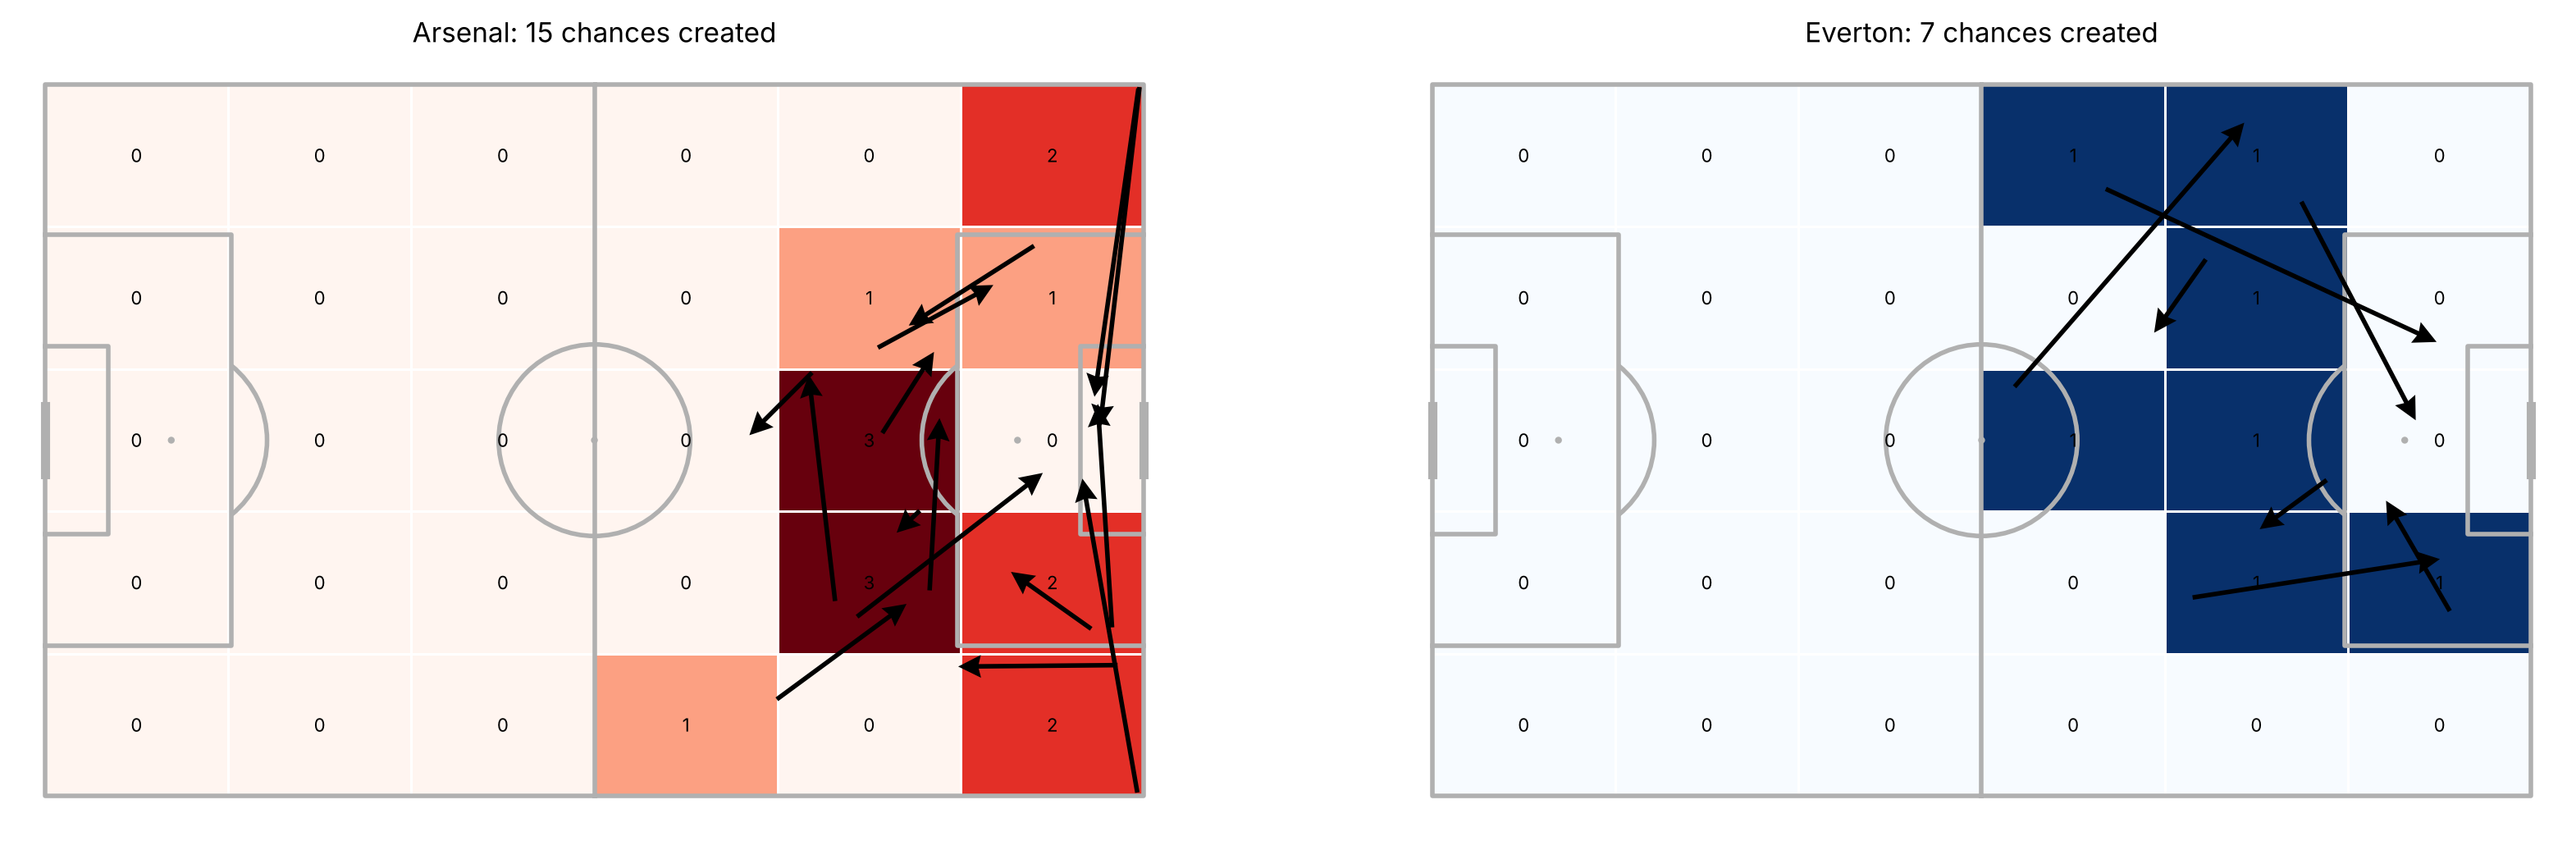

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(20, 7))
draw_chance_creation(axes[0], "Arsenal")
draw_chance_creation(axes[1], "Everton")
plt.show()

## Defensive actions

In [12]:
def draw_defensive_block(ax, team):
    def_types = ["Tackle", "Interception", "BallRecovery", "Clearance", "BlockedPass", "Aerial"]
    d = events[(events["team"] == team) & (events["type"].isin(def_types))]

    pitch = Pitch(pitch_type="opta", line_zorder=2)
    pitch.draw(ax=ax)

    pitch.kdeplot(d["x"], d["y"], ax=ax, fill=True, levels=50,
                  cmap=CMAPS[team], thresh=0.05)

    ax.set_title(f"{team}: {len(d)} defensive actions")

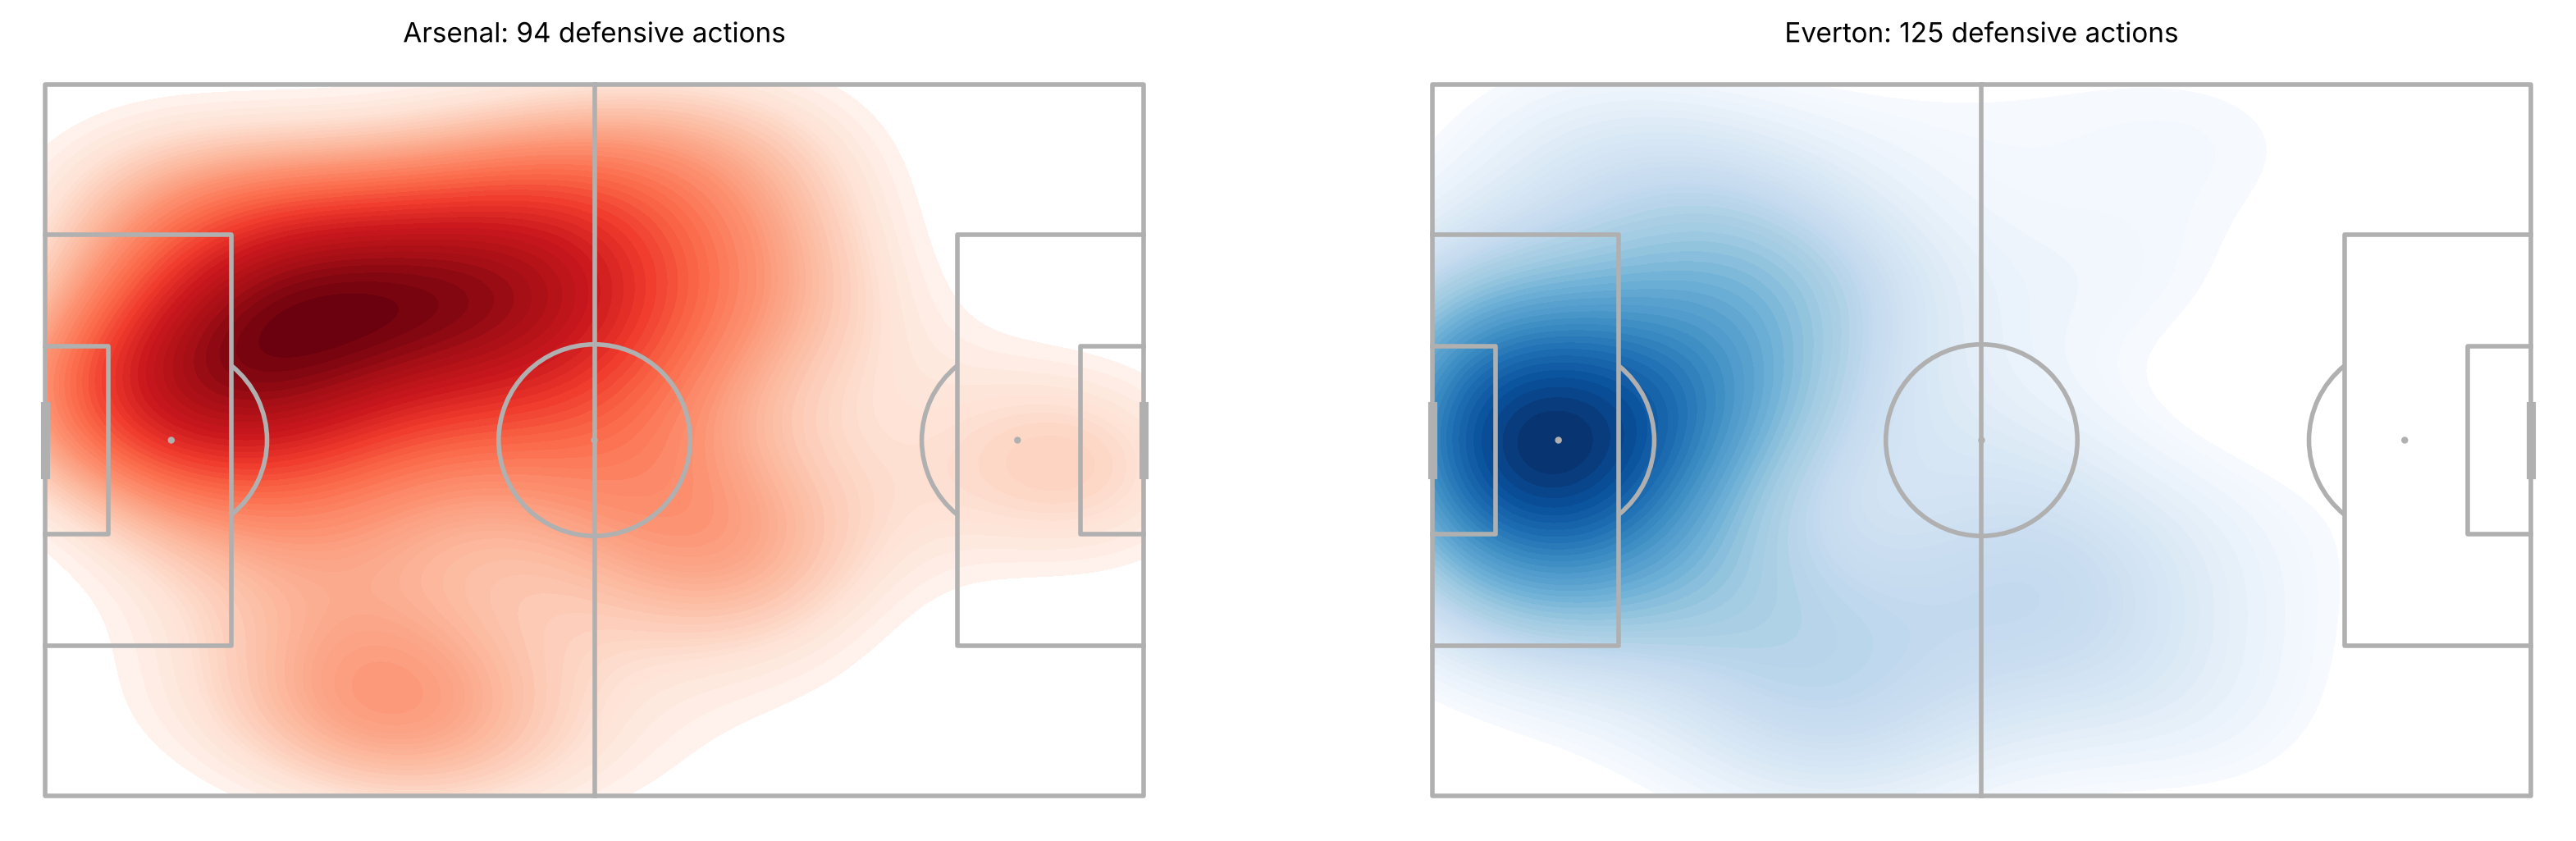

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(20, 7))
draw_defensive_block(axes[0], "Arsenal")
draw_defensive_block(axes[1], "Everton")
plt.show()

## High turnovers

In [14]:
def draw_high_turnovers(ax):
    pitch = Pitch(pitch_type="opta", line_zorder=2)
    pitch.draw(ax=ax)

    wins = events["type"].isin(["BallRecovery", "Interception"])
    won_tackle = (events["type"] == "Tackle") & (events["outcome_type"] == "Successful")
    near_goal = events["dist_start"] <= 40

    for team, flip in [(HOME, False), (AWAY, True)]:
        ht = events[(events["team"] == team) & (wins | won_tackle) & near_goal].copy()
        if flip:
           ht["x"] = 100 - ht["x"]
           ht["y"] = 100 - ht["y"]

        pitch.scatter(ht["x"], ht["y"], ax=ax, s=150, color=COLOURS[team],
                      edgecolors="black", label=f"{team} ({len(ht)})")

    ax.legend(loc="upper center", fontsize=8)
    ax.set_title("High turnovers: ball won within 40m of goal")

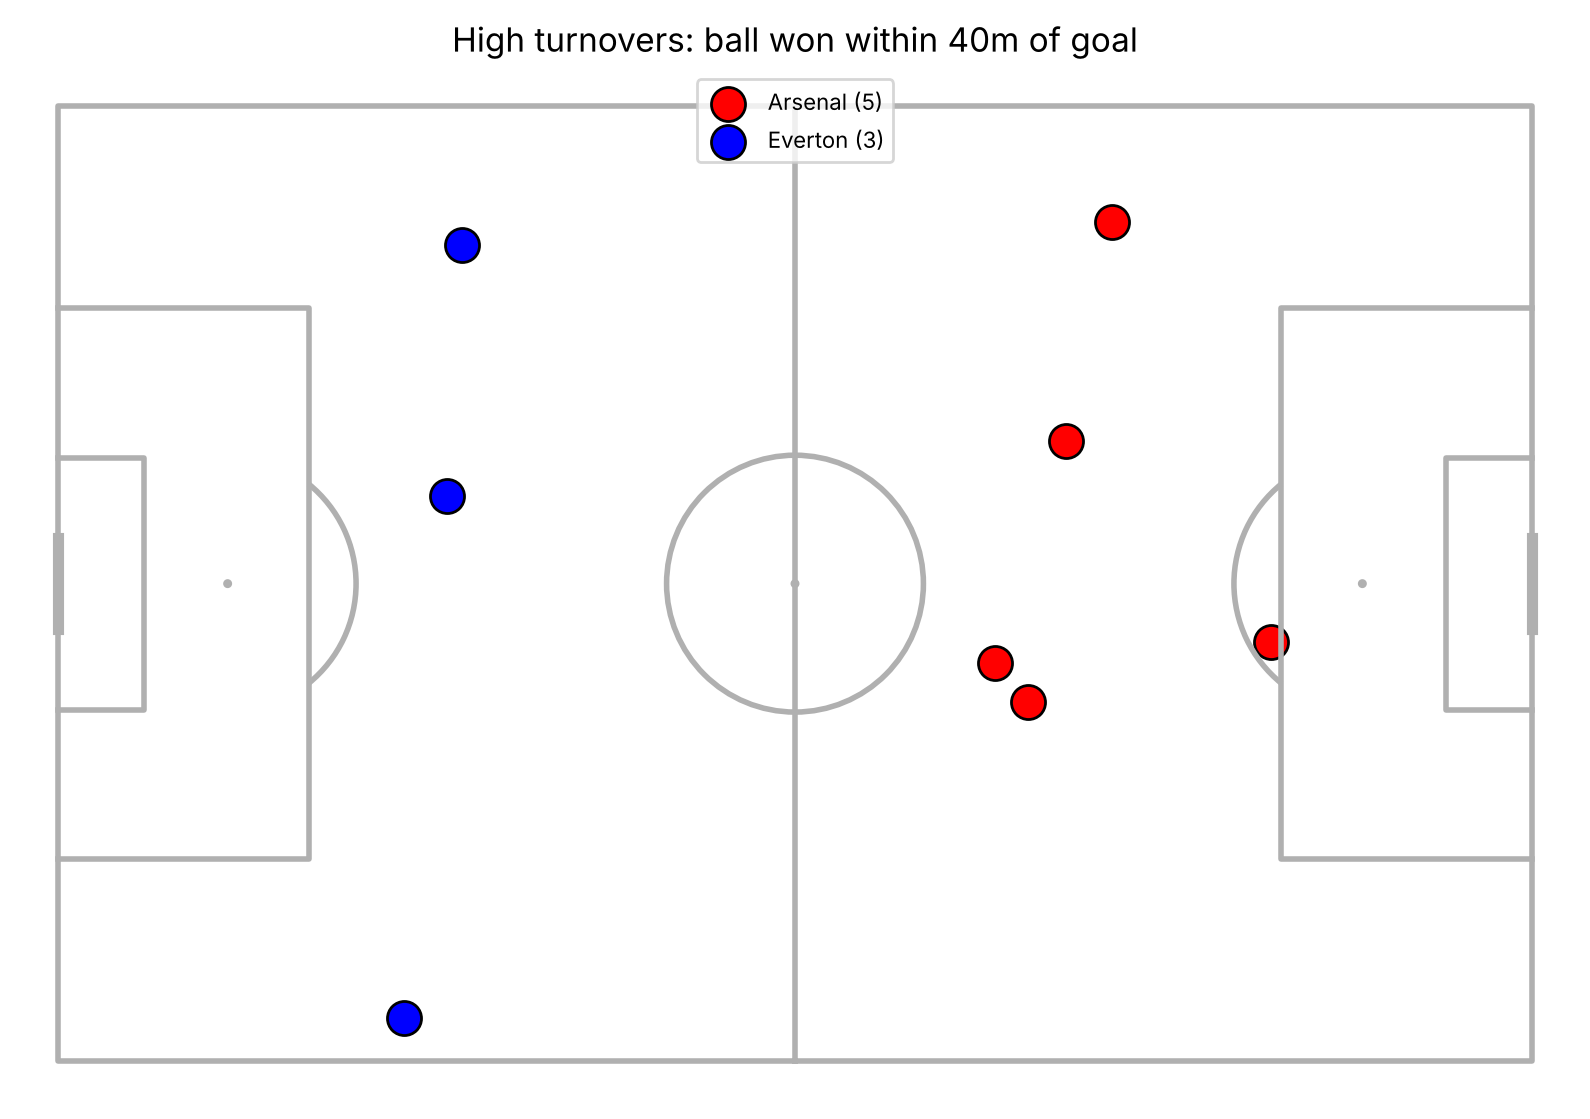

In [15]:
fig, ax = plt.subplots(figsize=(10, 7))
draw_high_turnovers(ax)
plt.show()

## Passing network

In [16]:
def draw_passing_network(ax, team):
    # 1. first substitution for this team
    subs = events[(events["type"] == "SubstitutionOn") & (events["team"] == team)]
    first_sub = subs["minute"].min()

    # 2. passes before the first sub that reached a teammate
    starters = completed_passes(team)
    starters = starters[(starters["minute"] < first_sub) & (starters["next_team"] == team)]

    # 3. dots: average position and number of passes per player
    avg = starters.groupby("player").agg(
        x=("x", "mean"),
        y=("y", "mean"),
        n=("x", "size"),
    )

    # 4. lines: count each passer -> receiver pair, keep the regular ones
    pairs = starters.groupby(["player", "next_player"]).size().reset_index(name="count")
    pairs = pairs[pairs["count"] >= 3]

    # 5. look up start and end positions
    pairs["x_start"] = pairs["player"].map(avg["x"])
    pairs["y_start"] = pairs["player"].map(avg["y"])
    pairs["x_end"] = pairs["next_player"].map(avg["x"])
    pairs["y_end"] = pairs["next_player"].map(avg["y"])
    pairs = pairs.dropna()

    # 6. stop arrows 80% of the way, so the heads aren't hidden under the dots
    pairs["x_arrow"] = pairs["x_start"] + 0.8 * (pairs["x_end"] - pairs["x_start"])
    pairs["y_arrow"] = pairs["y_start"] + 0.8 * (pairs["y_end"] - pairs["y_start"])

    # 7. draw: arrows (bottom), dots (top), names
    pitch = Pitch(pitch_type="opta", line_zorder=2)
    pitch.draw(ax=ax)

    for _, row in pairs.iterrows():
        pitch.arrows(row["x_start"], row["y_start"], row["x_arrow"], row["y_arrow"],
                     ax=ax, width=row["count"] * 0.5, headwidth=4, headlength=4,
                     color=COLOURS[team], alpha=0.6, zorder=1)

    pitch.scatter(avg["x"], avg["y"], ax=ax, s=avg["n"] * 15, color="white",
                  edgecolors=COLOURS[team], linewidth=2, zorder=2)

    for player, pos in avg.iterrows():
        pitch.annotate(player.split()[-1], xy=(pos["x"], pos["y"] + 4),
                       ax=ax, ha="center", fontsize=8, zorder=3)

    ax.set_title(f"{team}: passing network (until minute {first_sub})")

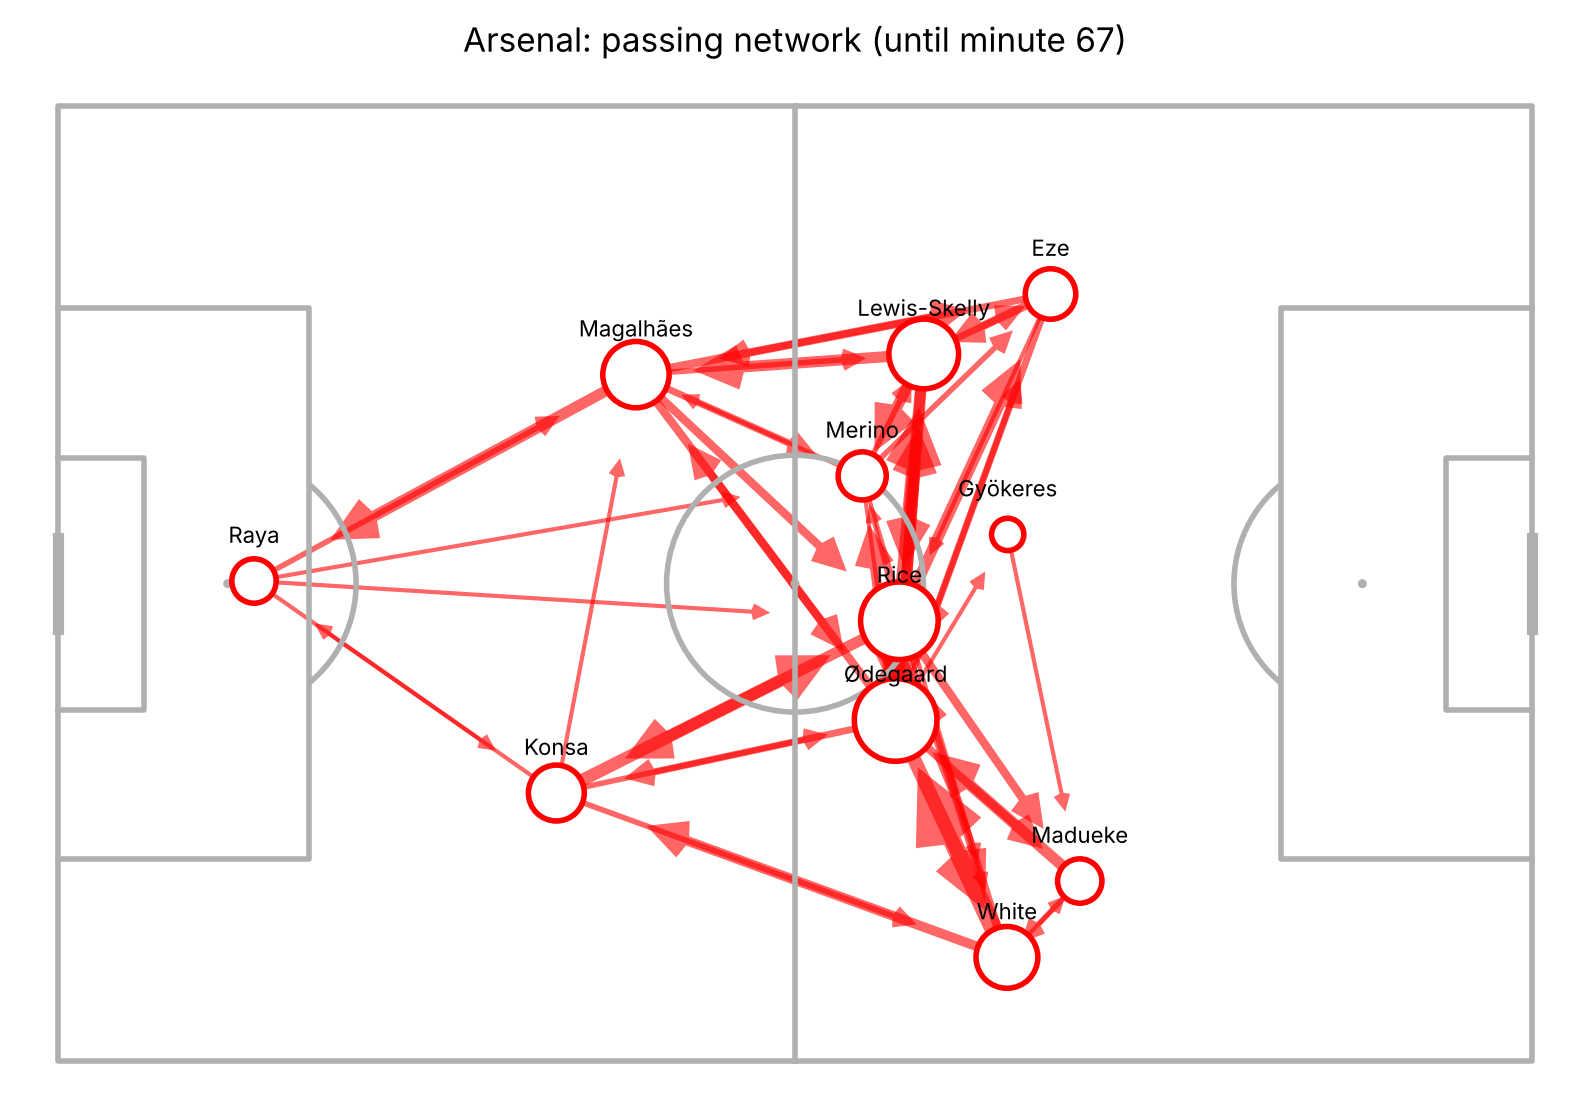

In [17]:
fig, ax = plt.subplots(figsize=(10, 7))
draw_passing_network(ax, "Arsenal")
plt.show()

## Zone 14 and the half-spaces

In [18]:
def draw_zone14(ax, team):
    p = completed_passes(team)
    p = p[~p["set_piece"]]

    in_z14 = p["end_x"].between(66.7, 83) & p["end_y"].between(33.3, 66.7)
    in_hs = p["end_x"].between(66.7, 100) & (
        p["end_y"].between(21.1, 36.8) | p["end_y"].between(63.2, 78.9)
    )
    z14 = p[in_z14]
    hs = p[in_hs]

    pitch = Pitch(pitch_type="opta", line_zorder=2)
    pitch.draw(ax=ax)

    ax.add_patch(Rectangle((66.7, 33.3), 83 - 66.7, 66.7 - 33.3, color="gold", alpha=0.2, zorder=1))
    ax.add_patch(Rectangle((66.7, 21.1), 100 - 66.7, 36.8 - 21.1, color=COLOURS[team], alpha=0.15, zorder=1))
    ax.add_patch(Rectangle((66.7, 63.2), 100 - 66.7, 78.9 - 63.2, color=COLOURS[team], alpha=0.15, zorder=1))

    pitch.arrows(z14["x"], z14["y"], z14["end_x"], z14["end_y"], ax=ax, width=1.5,
                 headwidth=5, color="orange", zorder=3, label=f"Zone 14 ({len(z14)})")
    pitch.arrows(hs["x"], hs["y"], hs["end_x"], hs["end_y"], ax=ax, width=1.5,
                 headwidth=5, color=COLOURS[team], zorder=3, label=f"Half-spaces ({len(hs)})")

    ax.legend(loc="upper left", fontsize=8)
    ax.set_title(f"{team}: zone 14 and half-spaces")

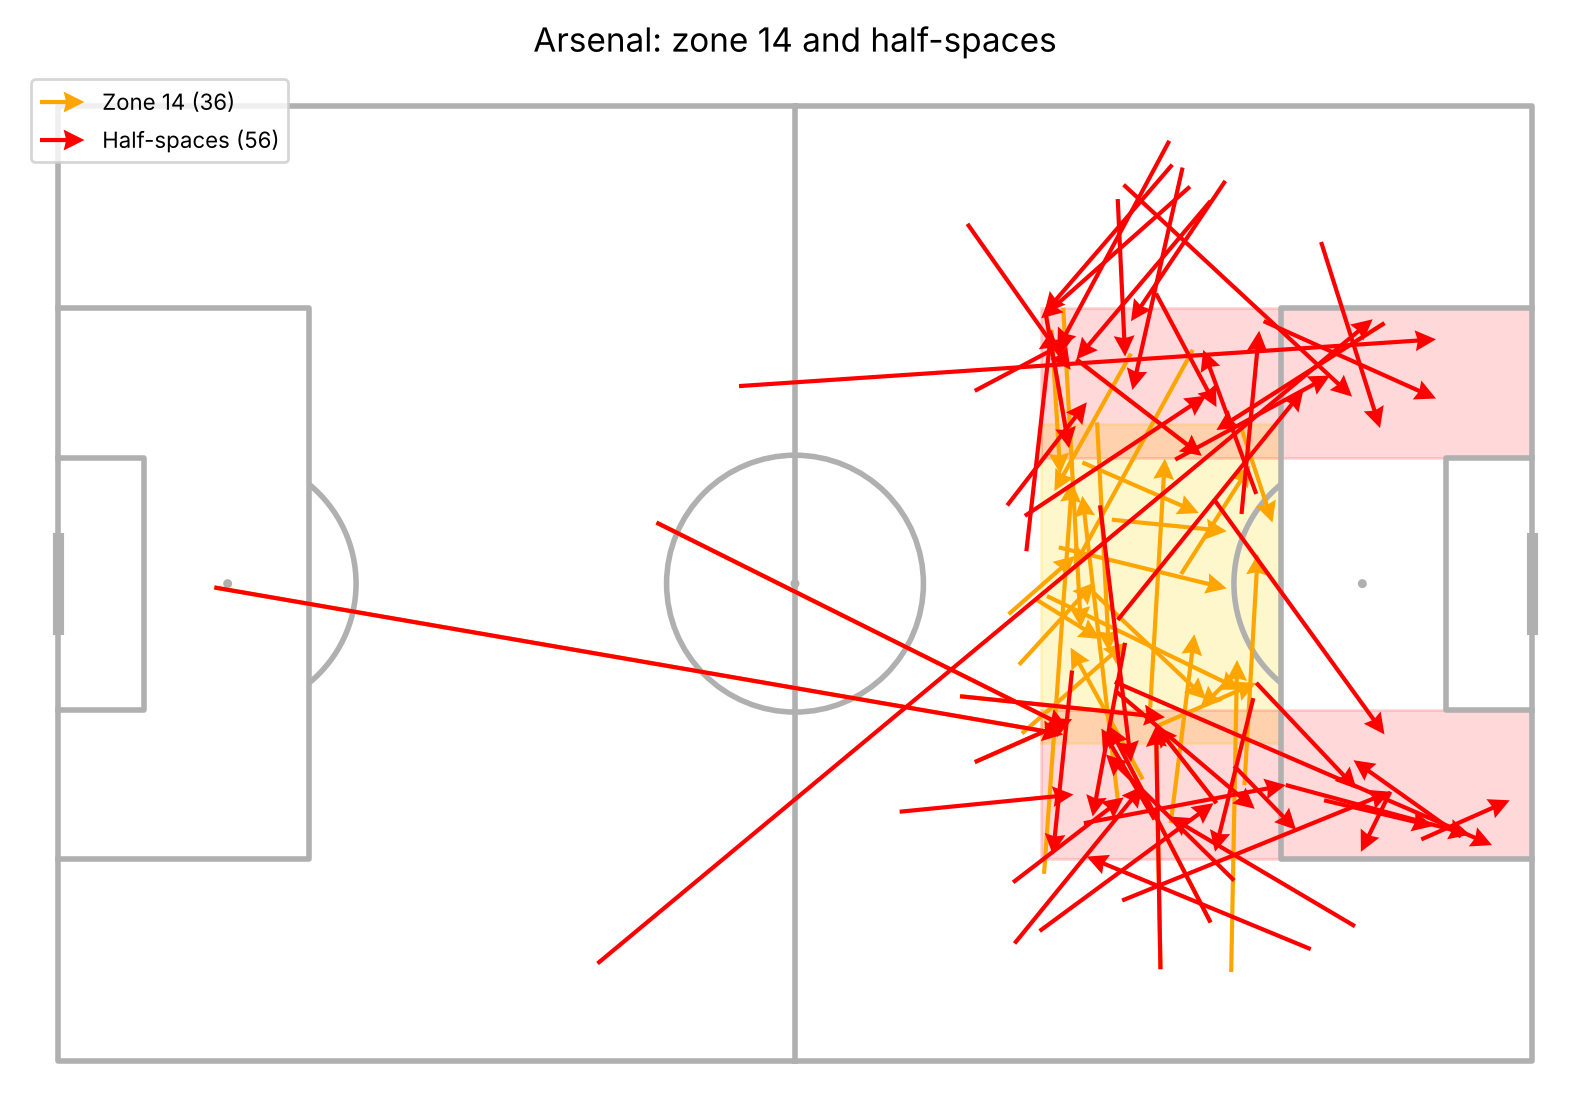

In [19]:
fig, ax = plt.subplots(figsize=(10, 7))
draw_zone14(ax, "Arsenal")
plt.show()

## Match momentum (xT per minute)

In [20]:
def draw_momentum(ax):
    for team, sign in [(HOME, 1), (AWAY, -1)]:
        per_min = completed_passes(team).groupby("minute")["xt"].sum()
        ax.bar(per_min.index, sign * per_min.values, color=COLOURS[team],
               label=f"{team} ({per_min.sum():.2f} xT)")

    ax.axhline(0, color="black", linewidth=1)

    home_goals = events[(events["team"] == HOME) & (events["is_goal"] == True)]["minute"]
    for m in home_goals:
        ax.axvline(m, color="green", linestyle="--", linewidth=1.5)

    ax.set_xlabel("Minute")
    ax.set_ylabel("xT added")
    ax.legend(loc="upper right", fontsize=8)
    ax.set_title("Match momentum by xT (dashed line = Arsenal goal)")

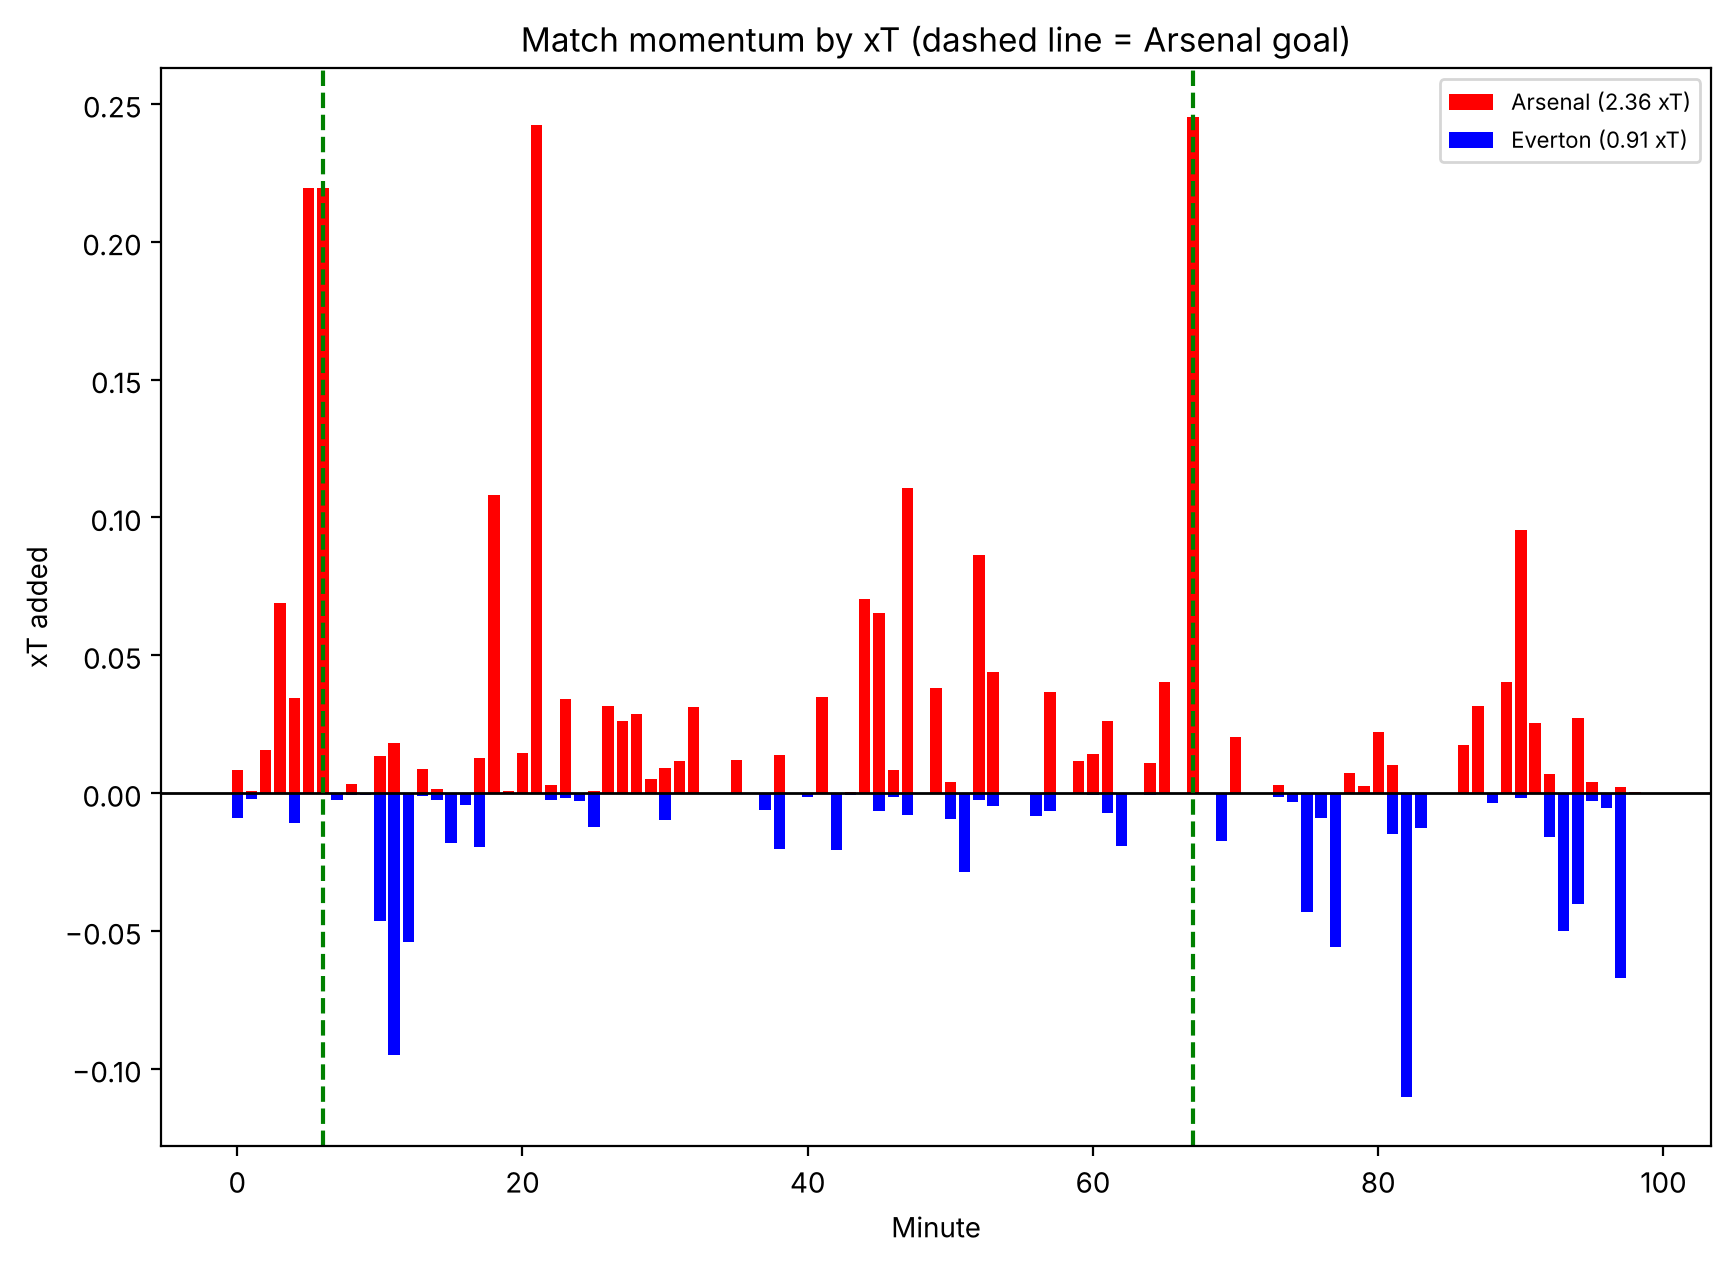

In [21]:
fig, ax = plt.subplots(figsize=(10, 7))
draw_momentum(ax)
plt.show()

## Key takeaways

In [22]:
import textwrap

def draw_takeaways(ax):
    ax.axis("off")

    points = [
        "Arsenal won 2–0 with both goals from centre-backs inside the six-yard box: "
        "Konsa from a corner (6') and Gabriel with a header from open play (67').",
        "Arsenal dominated the chances: 20 shots to 8 (14 v 5 on target) "
        "and 15 key passes to 7.",
        "They controlled the ball too: 569 passes to 401 (84.5% v 82.5% completed) "
        "and nearly twice as many completed passes into the final third (162 v 85).",
        "xT backs it up: 2.36 v 0.91. Rice (0.71) and Ødegaard (0.56) created the most "
        "threat with their passing, and Ødegaard was the hub of the passing network.",
        "Arsenal attacked through the middle: 20 of their 41 progressive passes went "
        "through the centre, with 36 passes into Zone 14 and 56 into the half-spaces "
        "(Everton: 15 and 22).",
        "Everton defended deep: 125 defensive actions to Arsenal's 94, made much closer "
        "to their own goal, and they went long more often (54 long balls v 44) despite "
        "having less of the ball.",
        "Arsenal pressed high late on: 5 high turnovers to Everton's 3, all of them "
        "after the 73rd minute as they closed the game out.",
    ]

    text = "KEY TAKEAWAYS\n\n" + "\n\n".join(
        textwrap.fill("• " + p, width=62, subsequent_indent="   ") for p in points
    )
    ax.text(0.02, 0.98, text, va="top", fontsize=11, transform=ax.transAxes,
            linespacing=1.3)

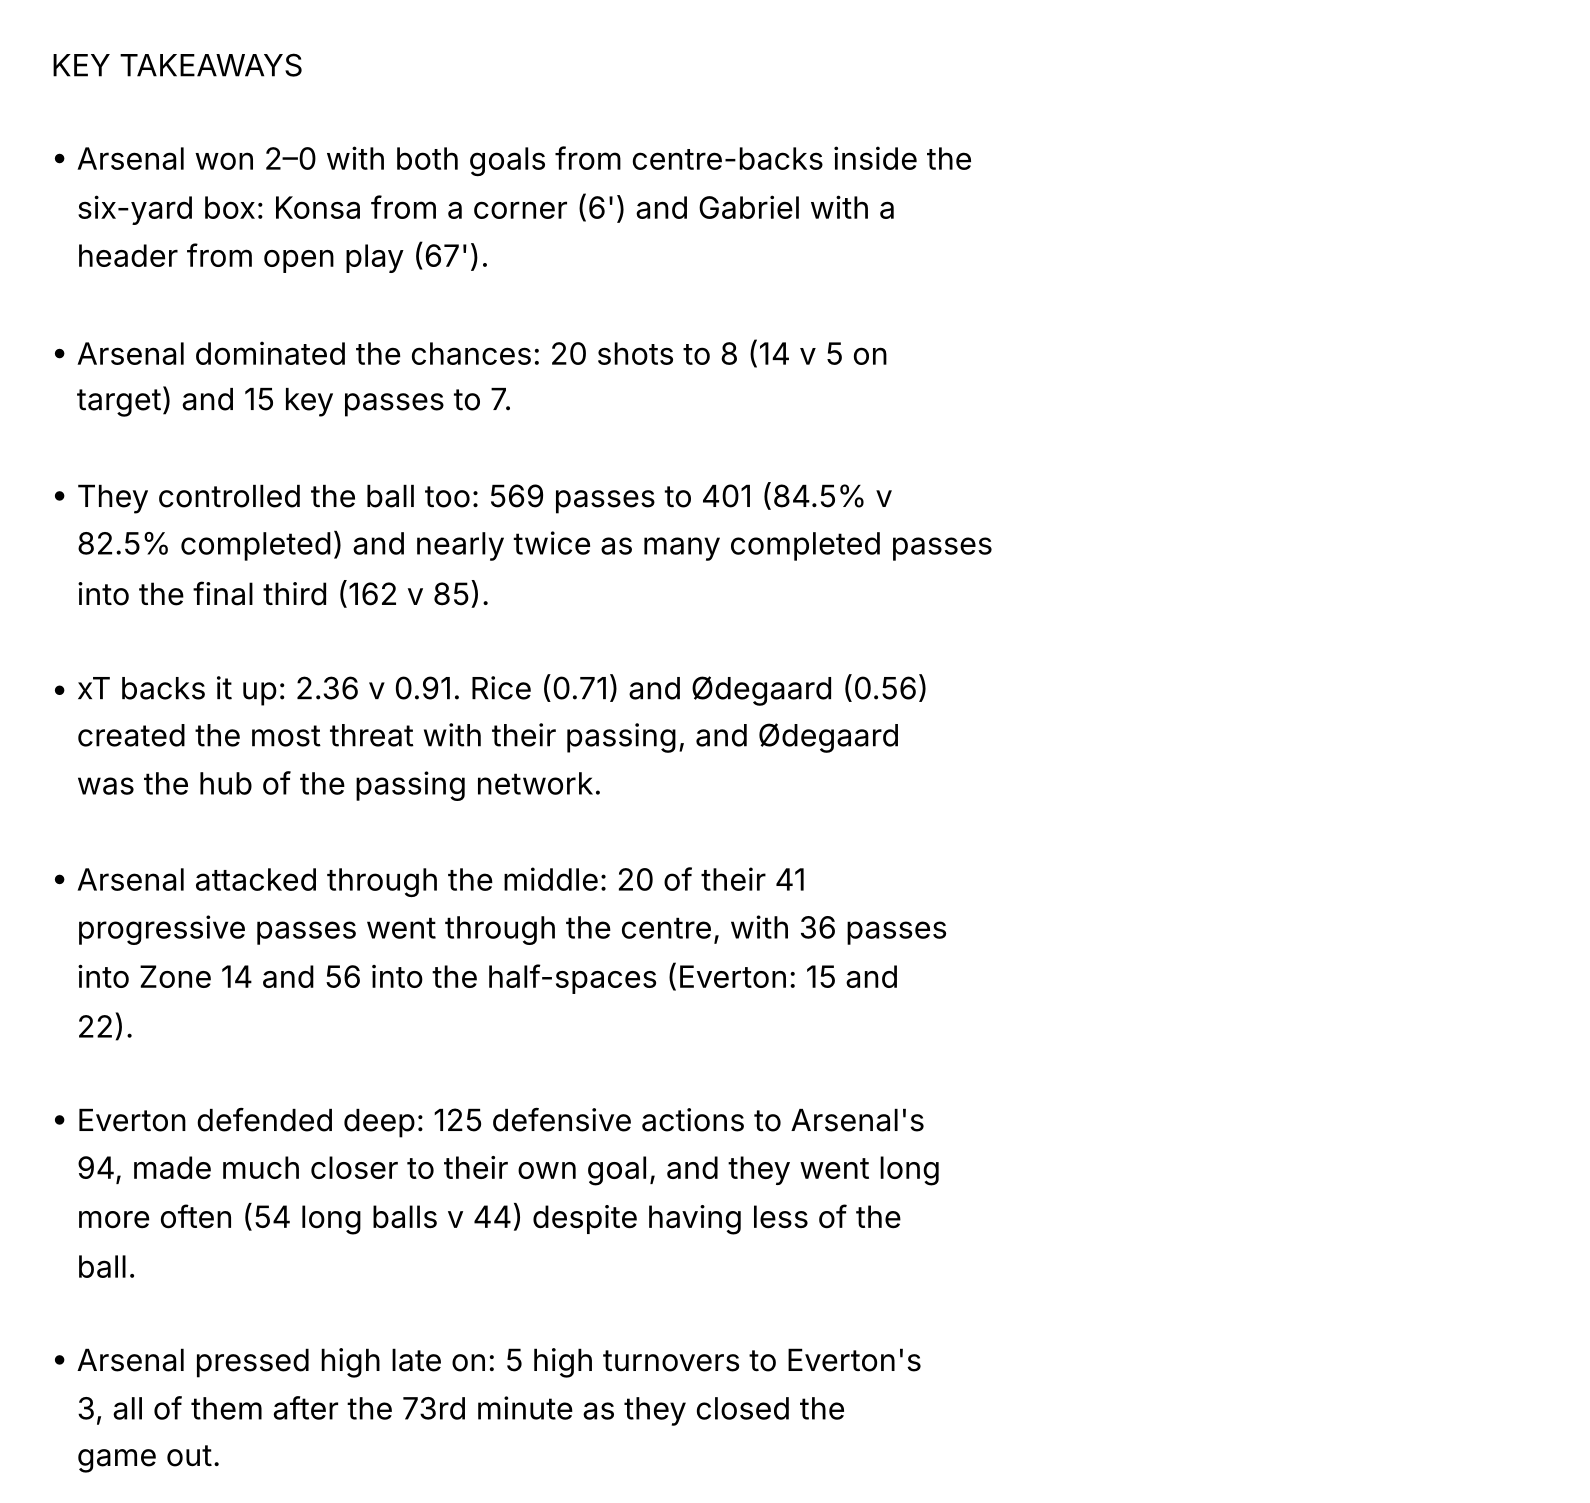

In [23]:
fig, ax = plt.subplots(figsize=(10, 7))
draw_takeaways(ax)
plt.show()

## The full report

Five rows × three columns: home team on the left, both teams / match-wide charts in the middle, away team on the right.

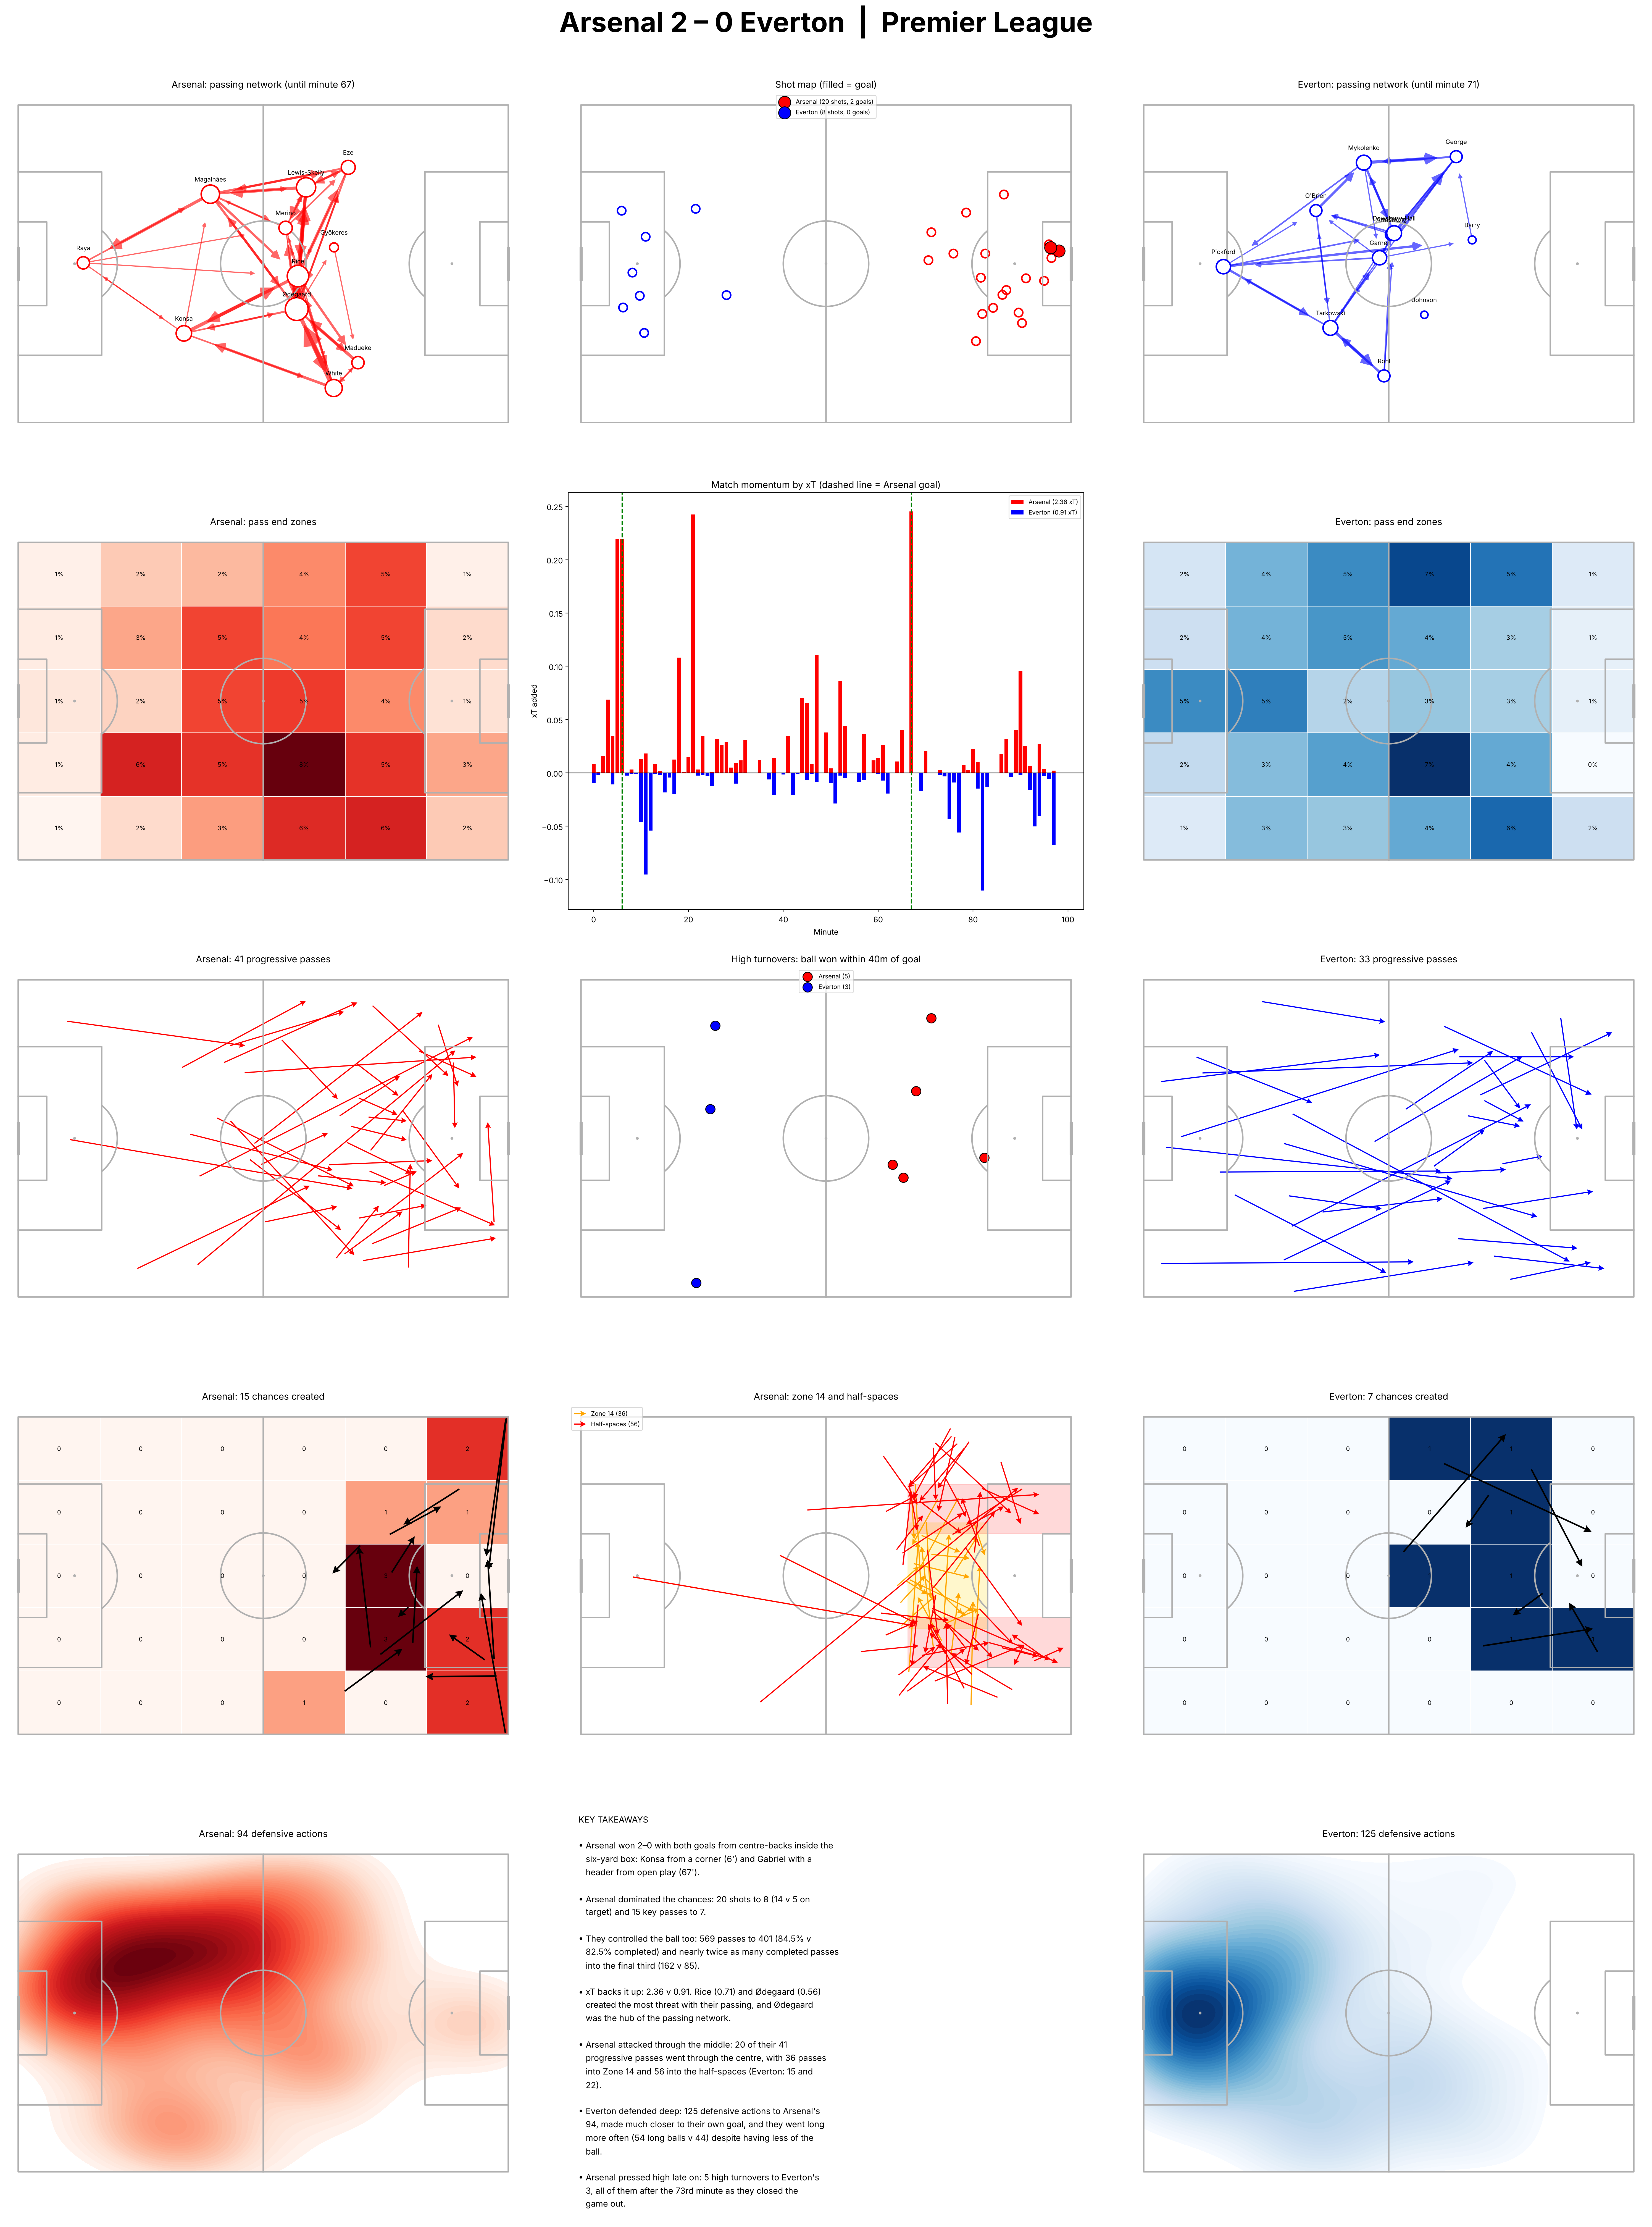

In [24]:
fig, axes = plt.subplots(5, 3, figsize=(30, 42))

# row 0
draw_passing_network(axes[0, 0], HOME)
draw_shot_map_both(axes[0, 1])
draw_passing_network(axes[0, 2], AWAY)

# row 1
draw_pass_end_zones(axes[1, 0], HOME)
draw_momentum(axes[1, 1])
draw_pass_end_zones(axes[1, 2], AWAY)

# row 2
draw_progressive(axes[2, 0], HOME)
draw_high_turnovers(axes[2, 1])
draw_progressive(axes[2, 2], AWAY)

# row 3
draw_chance_creation(axes[3, 0], HOME)
draw_zone14(axes[3, 1], HOME)
draw_chance_creation(axes[3, 2], AWAY)

# row 4
draw_defensive_block(axes[4, 0], HOME)
draw_takeaways(axes[4, 1])
draw_defensive_block(axes[4, 2], AWAY)

# header
home_goals = len(events[(events["team"] == HOME) & (events["is_goal"] == True)])
away_goals = len(events[(events["team"] == AWAY) & (events["is_goal"] == True)])
fig.suptitle(f"{HOME} {home_goals} – {away_goals} {AWAY}  |  Premier League",
             fontsize=36, fontweight="bold", y=1.0)

fig.tight_layout()
fig.savefig("match_report.png", dpi=100, bbox_inches="tight", facecolor="white")
plt.show()